# S18 · Calidad del aire en México · Notebook 01: preparación de datos

| | |
|---|---|
| **Programa** | IA Explorer – TCS / TecNM (CPFIA) |
| **Módulo** | 02 |
| **Sesión** | 18 · Excel para análisis de datos I |
| **Fecha** | 2026-11-11 |
| **Autor** | Luis Saúl González Guerra |

## 1. Objetivo

Preparar los datos públicos de calidad del aire de la OMS para analizarlos en Excel, siguiendo el proceso de la Sesión 18 (*De datos crudos a decisiones de negocio*).

Este notebook cubre las **etapas 1 y 2** del proceso: obtener los datos crudos y limpiarlos. El resultado es `data/processed/calidad_aire_mexico_limpio.xlsx`, una hoja simple sin fórmulas ni formato. Las etapas 3 a 8 (Tabla, fórmulas, tabla dinámica, gráficos, dashboard y decisión) se hacen a mano en Excel siguiendo `GUIA_EXCEL.md`, y el PDF final se arma con `02_reporte_pdf.ipynb` a partir de las capturas de ese trabajo.

Ejecuta las celdas una por una y lee la explicación de cada paso antes de correrlo.

### El Excel Mindset aplicado

| Pregunta | Métrica | Dimensión | Filtro | Análisis accionable |
|---|---|---|---|---|
| ¿Qué entidades de México respiran el aire más contaminado y cómo ha cambiado en el tiempo? | Promedio anual de PM2.5 en µg/m³ (`PROMEDIO`) | Entidad federativa (filas) y año (columnas) | Región y año | Priorizar las entidades donde invertir primero en control de emisiones y monitoreo |

## 2. Configuración

Imports, rutas relativas y constantes del análisis en una sola celda. Los valores guía son las **Guías de Calidad del Aire de la OMS 2021** (promedio anual).

In [1]:
import io
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd().parent
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
OUTPUT_DIR = BASE_DIR / "outputs"
for d in (RAW_DIR, PROCESSED_DIR, OUTPUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

WHO_URL = (
    "https://cdn.who.int/media/docs/default-source/air-pollution-documents/"
    "air-quality-and-health/who-ambient-air-quality-database-version-2026-v8.xlsx"
    "?sfvrsn=95d122a4_5&download=true"
)
RAW_FILE = RAW_DIR / "who_ambient_air_quality_database_v8_2026.xlsx"
XLSX_LIMPIO = PROCESSED_DIR / "calidad_aire_mexico_limpio.xlsx"

GUIA_OMS = {"PM2.5": 5, "PM10": 15, "NO2": 10}
COBERTURA_MINIMA = 75
PERIODO_RECIENTE = (2018, 2022)

AZUL, NARANJA, TINTA = "#2F5D8A", "#E8704A", "#1F2A36"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 3. Carga de datos (Etapa 1: Datos crudos)

**Fuente:** [WHO Ambient Air Quality Database, versión 8.0 (junio 2026)](https://www.who.int/publications/m/item/who-ambient-air-quality-database-(update-jun-2026)). Reúne promedios anuales de PM10, PM2.5 y NO2 medidos en estaciones terrestres de más de 7,000 asentamientos en el mundo. Para México, el origen de las mediciones es el **SINAICA del INECC**.

**Descripción:** cada fila es una ciudad o municipio en un año, con la concentración promedio anual de cada contaminante en µg/m³, el porcentaje de cobertura temporal de la medición, el número y tipo de estaciones y la población.

El archivo se descarga solo si no existe en `data/raw/`. El Excel original **no viene estructurado**: toda la fila es un texto CSV metido en la columna A, y las filas con textos largos se partieron en varias celdas. Es exactamente el problema de *Datos crudos* de la clase.

In [2]:
if not RAW_FILE.exists():
    req = urllib.request.Request(WHO_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as resp:
        RAW_FILE.write_bytes(resp.read())

crudo = pd.read_excel(RAW_FILE, header=None, dtype=str)
print(f"Forma del Excel original: {crudo.shape[0]:,} filas x {crudo.shape[1]} columnas")
print("Celdas con datos por columna:", crudo.notna().sum().to_dict())
crudo.head(3)

Forma del Excel original: 55,221 filas x 13 columnas
Celdas con datos por columna: {0: 55218, 1: 9473, 2: 2758, 3: 907, 4: 337, 5: 154, 6: 39, 7: 21, 8: 16, 9: 12, 10: 4, 11: 1, 12: 1}


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,"who_region,""iso3"",""country_name"",""city"",""year""...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"EMR,""AFG"",""Afghanistan"",""Kabul/AFG"",2019,""V5.0...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"EUR,""ALB"",""Albania"",""Durres/ALB"",2014,""V8.0 (2...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Reconstrucción equivalente a **Datos → Texto en columnas** de Excel: se unen los pedazos de cada fila y se interpreta el texto como CSV. Los valores `NA` se convierten en vacíos reales. La vista previa se muestra transpuesta (columnas como filas) para que se lean las 21 columnas.

In [3]:
lineas = crudo.apply(lambda fila: "".join(v for v in fila if isinstance(v, str)), axis=1)
mundo = pd.read_csv(io.StringIO("\n".join(lineas)), na_values=["NA"])
print(f"Base mundial: {mundo.shape[0]:,} registros, {mundo['country_name'].nunique()} países")
mundo.head(3).T

Base mundial: 55,214 registros, 126 países


,0,1,2
who_region,EMR,EUR,EUR
iso3,AFG,ALB,ALB
country_name,Afghanistan,Albania,Albania
city,Kabul/AFG,Durres/ALB,Durres/ALB
year,2019.0,2014.0,2015.0
version,V5.0 (2022) (n=1),V8.0 (2026) (n=1),V8.0 (2026) (n=1)
pm10_concentration,NaN,13.85,17.65
pm25_concentration,119.77,7.74,12.6
no2_concentration,NaN,36.74,26.63
pm10_tempcov,NaN,40.0,79.0


## 4. Exploración de datos (EDA)

Se revisa la base mundial y el subconjunto de México: tamaño, años, vacíos y calidad de la medición.

In [4]:
mex_crudo = mundo[mundo["iso3"] == "MEX"].copy()

print(f"Registros de México: {len(mex_crudo)}")
print(f"Municipios: {mex_crudo['city'].nunique()} | Años: {int(mex_crudo['year'].min())}-{int(mex_crudo['year'].max())}")
print("\nRegistros con medición por contaminante:")
print(mex_crudo[["pm25_concentration", "pm10_concentration", "no2_concentration"]].notna().sum())
mex_crudo[["pm25_concentration", "pm10_concentration", "no2_concentration",
           "pm25_tempcov", "pm10_tempcov", "no2_tempcov"]].describe().round(1)

Registros de México: 868
Municipios: 114 | Años: 2010-2023

Registros con medición por contaminante:
pm25_concentration    435
pm10_concentration    680
no2_concentration     591
dtype: int64


,pm25_concentration,pm10_concentration,no2_concentration,pm25_tempcov,pm10_tempcov,no2_tempcov
count,435.0,680.0,591.0,435.0,680.0,587.0
mean,21.9,51.1,62.7,88.0,90.2,85.7
std,7.7,16.4,82.3,8.2,8.2,19.2
min,4.8,20.7,3.8,17.0,16.0,13.0
25%,17.4,39.5,26.6,83.0,86.0,85.0
50%,21.0,48.7,39.5,89.0,92.0,92.0
75%,25.0,61.3,52.7,94.0,96.0,96.0
max,75.8,137.4,365.0,100.0,100.0,100.0


In [5]:
mex_crudo["city"].sample(8, random_state=1).tolist()

['Pachuca de Soto Hidalgo/MEX',
 'Pachuca de Soto Hidalgo/MEX',
 'Toluca Mexico/MEX',
 'Metepec Mexico/MEX',
 'Juarez Chihuahua/MEX',
 'Pachuca de Soto Hidalgo/MEX',
 'Nogales Sonora/MEX',
 'Garcia Nuevo Leon/MEX']

Hallazgos de la exploración que guían la limpieza:

- La columna `city` mezcla municipio, estado y país en un solo texto (`"Coyoacan Ciudad de Mexico/MEX"`).
- Hay nombres inconsistentes para el mismo municipio (`Cadereyta Jimenez` y `Cadereyta de Jimenez`; `Tlaquepaque` y `San Pedro Tlaquepaque`) y uno sin estado (`Soledad de Graciano Sanchez/MEX`).
- `type_of_stations` trae conteos pegados al texto (`"Urban (n=2)"`).
- Algunas mediciones cubren muy poco del año (cobertura temporal mínima de 13%), lo que distorsiona el promedio anual.
- Columnas como `reference`, `web_link` o `version` son de presentación o trazabilidad y no aportan al análisis.

## 5. Limpieza y transformación (Etapa 2: Datos limpios)

Se aplican las **Reglas de Higiene** de la clase. Cada regla se registra en una bitácora con su equivalente en Excel.

In [6]:
ESTADOS = {
    "Aguascalientes": "Aguascalientes", "Baja California": "Baja California", "Chihuahua": "Chihuahua",
    "Ciudad de Mexico": "Ciudad de México", "Coahuila": "Coahuila", "Durango": "Durango",
    "Guanajuato": "Guanajuato", "Hidalgo": "Hidalgo", "Jalisco": "Jalisco", "Mexico": "Estado de México",
    "Michoacan": "Michoacán", "Morelos": "Morelos", "Nayarit": "Nayarit", "Nuevo Leon": "Nuevo León",
    "Oaxaca": "Oaxaca", "Puebla": "Puebla", "Queretaro": "Querétaro", "San Luis Potosi": "San Luis Potosí",
    "Sonora": "Sonora", "Tabasco": "Tabasco", "Tlaxcala": "Tlaxcala", "Veracruz": "Veracruz",
    "Yucatan": "Yucatán", "Zacatecas": "Zacatecas",
}
REGIONES = {
    "Norte": ["Baja California", "Sonora", "Chihuahua", "Coahuila", "Nuevo León", "Durango"],
    "Occidente-Bajío": ["Jalisco", "Nayarit", "Guanajuato", "Querétaro", "Aguascalientes",
                        "Zacatecas", "San Luis Potosí", "Michoacán"],
    "Centro": ["Ciudad de México", "Estado de México", "Hidalgo", "Morelos", "Puebla", "Tlaxcala"],
    "Sur-Sureste": ["Veracruz", "Tabasco", "Oaxaca", "Yucatán"],
}
REGION_DE = {estado: region for region, estados in REGIONES.items() for estado in estados}
CORRECCIONES_MUNICIPIO = {
    "Cadereyta Jimenez Nuevo Leon": "Cadereyta de Jimenez Nuevo Leon",
    "San Pedro Tlaquepaque Jalisco": "Tlaquepaque Jalisco",
    "Soledad de Graciano Sanchez": "Soledad de Graciano Sanchez San Luis Potosi",
}

bitacora = []

def registrar(regla, problema, filas, accion, excel):
    bitacora.append({"Regla": regla, "Problema detectado": problema, "Filas afectadas": int(filas),
                     "Acción": accion, "Equivalente en Excel": excel})

registrar("Estructura", "Cada fila es un texto CSV en la columna A, partido en varias celdas",
          len(crudo), "Unir los pedazos y separar por comas",
          "CONCAT de columnas + Datos > Texto en columnas")
registrar("Sin vacíos", "Valores escritos como texto 'NA'",
          int((lineas.str.count(",NA") > 0).sum()), "Convertir 'NA' en celda vacía",
          "Buscar y reemplazar 'NA' por vacío")
registrar("Separación estricta", "La base es mundial y solo interesa México",
          len(mundo) - len(mex_crudo), "Filtrar iso3 = MEX", "Filtro automático por país")

mex = mex_crudo.copy()
lugar = mex["city"].str.replace("/MEX", "", regex=False).str.strip()
afectadas = lugar.isin(CORRECCIONES_MUNICIPIO).sum()
lugar = lugar.replace(CORRECCIONES_MUNICIPIO)
registrar("Estandarización", "Mismo municipio con dos nombres y un municipio sin estado", afectadas,
          "Unificar nombre y completar el estado", "Buscar y reemplazar / BUSCARV a un catálogo")

def separar_lugar(texto):
    for clave in sorted(ESTADOS, key=len, reverse=True):
        if texto.endswith(" " + clave):
            return texto[: -len(clave) - 1].strip(), ESTADOS[clave]
    return texto, None

mex[["Municipio", "Estado"]] = lugar.apply(lambda t: pd.Series(separar_lugar(t)))
assert mex["Estado"].notna().all(), mex.loc[mex["Estado"].isna(), "city"].unique()
registrar("Separación estricta", "Municipio, estado y país juntos en la columna city", len(mex),
          "Separar en Municipio y Estado y poner acentos al estado", "Texto en columnas / IZQUIERDA, EXTRAE")

mex["Region"] = mex["Estado"].map(REGION_DE)
tipo_sin_dato = mex["type_of_stations"].str.startswith("NA", na=True)
registrar("Separación estricta", "Tipo de estación viene como 'NA (n=1)': sin información para México",
          int(tipo_sin_dato.sum()), "No se lleva la columna a la tabla de análisis", "Eliminar columna")

for pref, nombre in (("pm25", "PM2.5"), ("pm10", "PM10"), ("no2", "NO2")):
    baja = mex[f"{pref}_tempcov"] < COBERTURA_MINIMA
    registrar("Datos confiables", f"{nombre}: medición con cobertura del año menor a {COBERTURA_MINIMA}%",
              int((baja & mex[f"{pref}_concentration"].notna()).sum()),
              "Dejar la medición vacía para no distorsionar promedios", "SI(cobertura<75, \"\", valor)")
    mex.loc[baja, f"{pref}_concentration"] = np.nan

limpio = (mex.rename(columns={"year": "Anio", "pm25_concentration": "PM25", "pm10_concentration": "PM10",
                              "no2_concentration": "NO2", "number_stations": "Estaciones",
                              "population": "Poblacion", "latitude": "Latitud", "longitude": "Longitud"})
          [["Anio", "Estado", "Municipio", "Region", "PM25", "PM10", "NO2", "Estaciones",
            "Poblacion", "Latitud", "Longitud"]])
limpio["Anio"] = limpio["Anio"].astype(int)
limpio["Estaciones"] = limpio["Estaciones"].astype("Int64")
limpio["Poblacion"] = limpio["Poblacion"].round().astype("Int64")
limpio[["PM25", "PM10", "NO2"]] = limpio[["PM25", "PM10", "NO2"]].round(2)

duplicados = limpio.duplicated(["Anio", "Estado", "Municipio"]).sum()
registrar("Sin duplicados", "Mismo municipio y año repetido tras unificar nombres", duplicados,
          "Conservar un registro por municipio y año", "Datos > Quitar duplicados")
limpio = limpio.drop_duplicates(["Anio", "Estado", "Municipio"])

sin_medicion = limpio[["PM25", "PM10", "NO2"]].isna().all(axis=1)
registrar("Sin vacíos", "Registros sin ningún contaminante válido", sin_medicion.sum(),
          "Eliminar la fila completa", "Filtro por vacíos + eliminar filas")
limpio = limpio[~sin_medicion]
registrar("Separación estricta", "Columnas de presentación o trazabilidad (reference, web_link, version)",
          len(limpio), "No se llevan a la tabla de análisis", "Ocultar o eliminar columnas")

limpio = limpio.sort_values(["Anio", "Estado", "Municipio"]).reset_index(drop=True)
limpio.to_csv(PROCESSED_DIR / "calidad_aire_mexico_limpio.csv", index=False)
bitacora_df = pd.DataFrame(bitacora)
bitacora_df.to_csv(PROCESSED_DIR / "bitacora_limpieza.csv", index=False)

print(f"Tabla limpia: {limpio.shape[0]} filas x {limpio.shape[1]} columnas")
print(f"{limpio['Municipio'].nunique()} municipios en {limpio['Estado'].nunique()} entidades")
bitacora_df

Tabla limpia: 857 filas x 11 columnas
111 municipios en 24 entidades


,Regla,Problema detectado,Filas afectadas,Acción,Equivalente en Excel
0,Estructura,"Cada fila es un texto CSV en la columna A, par...",55221,Unir los pedazos y separar por comas,CONCAT de columnas + Datos > Texto en columnas
1,Sin vacíos,Valores escritos como texto 'NA',48666,Convertir 'NA' en celda vacía,Buscar y reemplazar 'NA' por vacío
2,Separación estricta,La base es mundial y solo interesa México,54346,Filtrar iso3 = MEX,Filtro automático por país
3,Estandarización,Mismo municipio con dos nombres y un municipio...,6,Unificar nombre y completar el estado,Buscar y reemplazar / BUSCARV a un catálogo
4,Separación estricta,"Municipio, estado y país juntos en la columna ...",868,Separar en Municipio y Estado y poner acentos ...,"Texto en columnas / IZQUIERDA, EXTRAE"
5,Separación estricta,Tipo de estación viene como 'NA (n=1)': sin in...,868,No se lleva la columna a la tabla de análisis,Eliminar columna
6,Datos confiables,PM2.5: medición con cobertura del año menor a 75%,6,Dejar la medición vacía para no distorsionar p...,"SI(cobertura<75, """", valor)"
7,Datos confiables,PM10: medición con cobertura del año menor a 75%,12,Dejar la medición vacía para no distorsionar p...,"SI(cobertura<75, """", valor)"
8,Datos confiables,NO2: medición con cobertura del año menor a 75%,41,Dejar la medición vacía para no distorsionar p...,"SI(cobertura<75, """", valor)"
9,Sin duplicados,Mismo municipio y año repetido tras unificar n...,0,Conservar un registro por municipio y año,Datos > Quitar duplicados


In [7]:
limpio.head()

,Anio,Estado,Municipio,Region,PM25,PM10,NO2,Estaciones,Poblacion,Latitud,Longitud
0,2010,Baja California,Mexicali,Norte,NaN,NaN,39.5,1,933123,32.63110,-115.44510
1,2010,Baja California,Tijuana,Norte,NaN,NaN,35.7,1,1579083,32.49750,-116.97690
2,2010,Chihuahua,Chihuahua,Norte,NaN,NaN,33.9,1,833160,28.71610,-106.13330
3,2010,Chihuahua,Juarez,Norte,NaN,65.72,NaN,5,1625,31.71574,-106.46564
4,2010,Ciudad de México,Alvaro Obregon,Centro,NaN,35.50,47.0,1,743088,19.32510,-99.20410


## 6. Exportar los datos limpios para Excel

Se guarda una sola hoja llamada `Datos`, sin fórmulas ni formato. Todo lo demás se construye a mano en Excel siguiendo `GUIA_EXCEL.md`.

In [8]:
with pd.ExcelWriter(XLSX_LIMPIO, engine="openpyxl") as writer:
    limpio.to_excel(writer, sheet_name="Datos", index=False)
print(f"Archivo para Excel: {XLSX_LIMPIO.relative_to(BASE_DIR)} ({len(limpio)} filas)")

Archivo para Excel: data/processed/calidad_aire_mexico_limpio.xlsx (857 filas)


## 7. Valores de referencia para comprobar tu Excel

Pandas calcula lo mismo que vas a construir en Excel. Cuando termines cada etapa de la guía, compara tus resultados con estas tablas: si coinciden, tu Excel está bien.

**Etapa 4. Columnas calculadas:** `Veces_Guia_PM25` (cuántas veces supera la guía OMS) y `Categoria_PM25` con una función `SI` anidada sobre los objetivos intermedios de la OMS 2021.

In [9]:
def categoria_pm25(valor):
    if pd.isna(valor):
        return "Sin dato"
    if valor > 35:
        return "Muy alto (>35)"
    if valor > 25:
        return "Alto (25-35)"
    if valor > 15:
        return "Moderado (15-25)"
    if valor > 10:
        return "Bajo (10-15)"
    if valor > 5:
        return "Cerca de guía (5-10)"
    return "Cumple guía (≤5)"

referencia = limpio.copy()
referencia["Veces_Guia_PM25"] = (referencia["PM25"] / GUIA_OMS["PM2.5"]).round(2)
referencia["Categoria_PM25"] = referencia["PM25"].apply(categoria_pm25)
referencia["Categoria_PM25"].value_counts()

Categoria_PM25
Sin dato                428
Moderado (15-25)        255
Alto (25-35)             91
Bajo (10-15)             68
Muy alto (>35)           12
Cumple guía (≤5)          2
Cerca de guía (5-10)      1
Name: count, dtype: int64

**Etapa 4. Fórmulas base:** resultados esperados en la hoja de fórmulas.

In [10]:
formulas_ref = pd.DataFrame({
    "Fórmula en Excel": ["=SUMA(tblCalidadAire[Estaciones])", "=PROMEDIO(tblCalidadAire[PM25])",
                         "=CONTAR(tblCalidadAire[PM25])", "=CONTARA(tblCalidadAire[Municipio])",
                         '=CONTAR.SI(tblCalidadAire[PM25],"<=5")'],
    "Resultado esperado": [int(limpio["Estaciones"].sum()), round(limpio["PM25"].mean(), 1),
                           int(limpio["PM25"].count()), int(limpio["Municipio"].count()),
                           int((limpio["PM25"] <= GUIA_OMS["PM2.5"]).sum())],
})
formulas_ref["Resultado esperado"] = formulas_ref["Resultado esperado"].map(lambda v: f"{v:g}")
formulas_ref

,Fórmula en Excel,Resultado esperado
0,=SUMA(tblCalidadAire[Estaciones]),1288
1,=PROMEDIO(tblCalidadAire[PM25]),21.8
2,=CONTAR(tblCalidadAire[PM25]),429
3,=CONTARA(tblCalidadAire[Municipio]),857
4,"=CONTAR.SI(tblCalidadAire[PM25],""<=5"")",2


**Etapa 5. Tabla dinámica:** promedio de PM25 con *Estado* en filas y *Año* en columnas. Tu tabla dinámica de Excel debe mostrar estos mismos números, incluida la fila y columna *Total general*.

In [11]:
pivote_pm25 = limpio.pivot_table(index="Estado", columns="Anio", values="PM25", aggfunc="mean").round(1)
pivote_pm25["Total general"] = limpio.groupby("Estado")["PM25"].mean().round(1)
pivote_pm25 = pivote_pm25.dropna(subset=["Total general"])
pivote_pm25.loc["Total general"] = list(limpio.groupby("Anio")["PM25"].mean().round(1)) + [round(limpio["PM25"].mean(), 1)]
pivote_pm25.to_csv(PROCESSED_DIR / "referencia_tabla_dinamica.csv")
pivote_pm25

Anio,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,Total general
Estado,,,,,,,,,,,,,,,
Aguascalientes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.6,NaN,NaN,NaN,NaN,NaN,24.6
Baja California,NaN,NaN,NaN,NaN,23.9,22.2,NaN,21.7,23.0,24.9,21.0,32.0,28.8,NaN,24.9
Chihuahua,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.9,16.6,NaN,14.1,13.6,39.9,NaN,20.0
Ciudad de México,22.5,25.9,23.8,25.0,22.7,24.5,22.7,21.8,22.8,21.9,19.2,19.1,20.2,20.8,22.5
Coahuila,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.3,NaN,18.8,20.1,18.9,12.8,NaN,17.6
Durango,NaN,NaN,NaN,NaN,NaN,19.0,22.3,NaN,17.6,NaN,18.3,18.4,NaN,NaN,19.1
Estado de México,22.8,29.0,28.4,29.7,26.5,28.0,27.4,31.7,27.9,25.8,24.8,27.7,24.6,20.1,26.9
Guanajuato,NaN,NaN,NaN,NaN,20.7,19.2,19.8,20.1,16.1,16.6,16.2,16.1,16.5,NaN,17.3
Hidalgo,NaN,NaN,NaN,61.8,50.4,33.0,21.4,19.8,20.4,17.1,16.8,17.1,18.9,NaN,23.8


**Etapa 7. KPIs del dashboard** para el periodo 2018-2022. Los usarás para comprobar los indicadores de tu dashboard y para escribir la decisión.

In [12]:
ini, fin = PERIODO_RECIENTE
reciente = limpio[limpio["Anio"].between(ini, fin)]

resumen_estado = (reciente.groupby("Estado")
                  .agg(PM25=("PM25", "mean"), PM10=("PM10", "mean"), NO2=("NO2", "mean"),
                       Municipios=("Municipio", "nunique"))
                  .round(1).sort_values("PM25", ascending=False))
tendencia = limpio.groupby("Anio")[["PM25", "PM10", "NO2"]].mean().round(1)
conteo_tendencia = limpio.groupby("Anio")["PM25"].count()

kpi = {
    "pm25_nacional": reciente["PM25"].mean(),
    "pm10_nacional": reciente["PM10"].mean(),
    "no2_nacional": reciente["NO2"].mean(),
    "pct_sobre_guia_pm25": (reciente["PM25"].dropna() > GUIA_OMS["PM2.5"]).mean() * 100,
    "pct_sobre_oi4": (reciente["PM25"].dropna() > 10).mean() * 100,
    "municipios": len(limpio[["Municipio", "Estado"]].drop_duplicates()),
    "estados": limpio["Estado"].nunique(),
    "estados_pm25": limpio.dropna(subset=["PM25"])["Estado"].nunique(),
}
kpi["veces_guia"] = kpi["pm25_nacional"] / GUIA_OMS["PM2.5"]
top3 = resumen_estado["PM25"].dropna().head(3)
peor_muni = (reciente.groupby(["Municipio", "Estado"])["PM25"].mean().dropna()
             .sort_values(ascending=False).head(5).round(1))
pd.Series({
    f"PM2.5 promedio {ini}-{fin} (µg/m³)": round(kpi["pm25_nacional"], 1),
    "Veces sobre la guía OMS": round(kpi["veces_guia"], 1),
    f"% de mediciones de PM2.5 sobre la guía ({ini}-{fin})": round(kpi["pct_sobre_guia_pm25"], 1),
    "Municipios monitoreados": kpi["municipios"],
    "Entidades con estaciones": kpi["estados"],
    "Entidades que miden PM2.5": kpi["estados_pm25"],
}, name="Valor esperado").map(lambda v: f"{v:g}").to_frame()

,Valor esperado
PM2.5 promedio 2018-2022 (µg/m³),19.6
Veces sobre la guía OMS,3.9
% de mediciones de PM2.5 sobre la guía (2018-2022),99.2
Municipios monitoreados,112
Entidades con estaciones,24
Entidades que miden PM2.5,22


In [13]:
peor_muni

Municipio           Estado          
San Mateo Atenco    Estado de México    35.5
Guadalajara         Jalisco             29.9
Metepec             Estado de México    29.5
Toluca              Estado de México    29.0
Atotonilco de Tula  Hidalgo             28.4
Name: PM25, dtype: float64

Municipios con mayor PM2.5 en el periodo y **contexto mundial**: promedio de PM2.5 de las ciudades con medición en cada región de la OMS, en el mismo periodo. Las regiones no tienen la misma cantidad de ciudades monitoreadas, así que la comparación es orientativa.

In [14]:
REGIONES_OMS = {"AFR": "África", "AMR": "Américas", "EMR": "Mediterráneo Oriental", "EUR": "Europa",
                "SEAR": "Asia Sudoriental", "WPR": "Pacífico Occidental"}
mundo_rec = mundo[mundo["year"].between(ini, fin)]
comparacion = (mundo_rec.groupby("who_region")["pm25_concentration"].mean()
               .rename(index=REGIONES_OMS).to_frame("PM25"))
comparacion.loc["México"] = kpi["pm25_nacional"]
comparacion.loc["Mundo"] = mundo_rec["pm25_concentration"].mean()
comparacion = comparacion.round(1).sort_values("PM25", ascending=False)
paises = mundo_rec.groupby("country_name")["pm25_concentration"].mean().dropna()
rank_mexico = int(paises.rank(ascending=False)["Mexico"])
print(f"México ocupa el lugar {rank_mexico} de {len(paises)} países con dato de PM2.5 ({ini}-{fin}).")
comparacion

México ocupa el lugar 45 de 101 países con dato de PM2.5 (2018-2022).


,PM25
who_region,
Mediterráneo Oriental,49.1
Asia Sudoriental,38.9
Pacífico Occidental,33.5
África,27.7
México,19.6
Mundo,19.0
Europa,12.8
Américas,10.7


## 8. Contexto mundial

Gráfica que se agrega al reporte PDF: México frente a las regiones de la OMS en el mismo periodo.

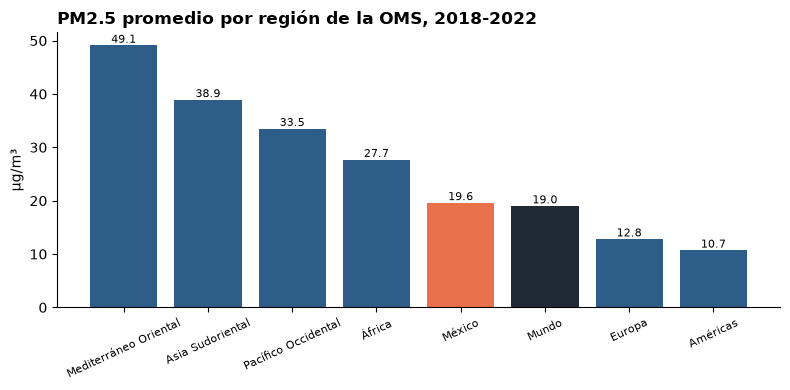

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
colores = [NARANJA if r == "México" else (TINTA if r == "Mundo" else AZUL) for r in comparacion.index]
ax.bar(comparacion.index, comparacion["PM25"], color=colores)
for x, v in enumerate(comparacion["PM25"]):
    ax.text(x, v + 0.5, f"{v:.1f}", ha="center", fontsize=8)
ax.set_title(f"PM2.5 promedio por región de la OMS, {ini}-{fin}", loc="left", fontweight="bold")
ax.set_ylabel("µg/m³")
ax.tick_params(axis="x", labelrotation=25, labelsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "pm25_contexto_mundial.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Siguiente paso

1. Abre `data/processed/calidad_aire_mexico_limpio.xlsx` en Excel y guárdalo como `outputs/S18_Calidad_Aire_Mexico.xlsx`.
2. Sigue `GUIA_EXCEL.md` paso a paso y guarda cada captura en `outputs/capturas/` con el nombre que indica la guía.
3. Compara tus resultados con las tablas de la sección 7.
4. Escribe tus textos y genera el PDF con `02_reporte_pdf.ipynb`.

## 10. Referencias

- World Health Organization. *WHO Ambient Air Quality Database, version 8.0 (update June 2026)*. https://www.who.int/publications/m/item/who-ambient-air-quality-database-(update-jun-2026)
- World Health Organization (2021). *WHO global air quality guidelines*.
- INECC. Sistema Nacional de Información de la Calidad del Aire (SINAICA). https://sinaica.inecc.gob.mx/
- TCS Empowers / TecNM CPFIA. *Sesión 18: Excel para análisis de datos I*.